[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/QPATE_PrivateAggregation_Watkins2024.ipynb)

# QPATE: quantum Private Aggregation of Teacher Ensembles on MNIST 0 vs 1: Watkins et al. (2024) step by step

**Paper.** William Watkins, Heehwan Wang, Sangyoon Bae, Huan-Hsin Tseng, Jiook Cha, Samuel Yen-Chi Chen, Shinjae Yoo,
*Quantum Privacy Aggregation of Teacher Ensembles (QPATE) for Privacy-Preserving Quantum Machine Learning*,
IEEE ICASSP 2024, DOI 10.1109/ICASSP48485.2024.10447786 (arXiv:2401.07464).

**What this notebook does.** PATE (Papernot et al. 2017) protects a training set by never letting the released model see it.
The private data are split into disjoint shards; one *teacher* is trained on each shard; a *student* is trained on public,
unlabelled data whose labels come from a **noisy vote** of the teachers (Laplace noise added to the vote counts, then argmax).
The student is the only model released, and its privacy cost is bounded by the number of times it queried the teachers,
which is tracked with the moments accountant. QPATE replaces the teachers and the student by hybrid quantum-classical
networks: two convolution blocks, a linear layer down to 10 numbers, and a 10-qubit variational quantum circuit (VQC) with 60
trainable parameters. The paper compares it with classical PATE (four convolution blocks) on MNIST digits 0 versus 1.

This notebook rebuilds the whole pipeline from scratch:

1. downloads MNIST (Hugging Face parquet mirror), keeps the digits 0 and 1, pads them to 32 x 32 and shows the real data;
2. builds the classical network and the hybrid network; the VQC is simulated by a fast batched PyTorch state-vector engine whose
   output and gradients are **asserted equal to a real PennyLane QNode** (`default.qubit`), which is also drawn;
3. implements the PATE machinery: disjoint teachers, Laplace noisy-argmax aggregation, a student trained on the noisy labels,
   and the moments accountant of Papernot et al. (data-independent and data-dependent bound) written out in NumPy;
4. runs the experiment of the paper (4 teachers, 20 epochs, accuracy of classical versus quantum PATE for four privacy
   settings) over several seeds and re-draws Table 1 and Fig. 4;
5. goes one step beyond the paper: it asks what privacy budget the accountant really certifies for those runs, and how large the
   budget must be before four teachers can label anything usefully.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` (class demo, 5 to 10 minutes) uses 3 seeds,
smaller shards and 6 epochs; `FAST_MODE = False` uses the paper's sizes and epochs (1000 samples per teacher, 20 epochs; the paper averages 10 seeds, 4 seeds take about 2.5 hours on a loaded shared CPU and 10 seeds longer; set `N_SEEDS = 10` to match the paper). No Hugging Face token and no quantum hardware are needed (MNIST is public).

**Shipped mode.** This notebook was shipped with `FAST_MODE = True` (the full run exceeds the 90-minute budget on a shared CPU); its results therefore come from small shards and 6 epochs and are noisier than the paper's.

**What you get at the end.** Table 1 and Fig. 4 re-drawn from your own run, the privacy budget certified by the accountant,
a table that puts the paper's numbers next to this notebook's with a verdict per claim, a critical reading and exercises.

## The paper in one page

* **Problem.** A released ML model can leak its (private) training data. Differential privacy (DP) bounds that leak by an
  `(epsilon, delta)` budget; the lower `epsilon`, the stronger the protection. DP-SGD (clip and noise the gradients) was already
  applied to QML by Watkins et al. (2023). QPATE instead leaves the optimiser untouched and puts the privacy in the *labels*.
* **Method (PATE).** `n` teachers are trained on `n` disjoint shards. For a public sample `x`, the vote count of class `j` is
  `n_j(x)`; the aggregated label is `argmax_j ( n_j(x) + Lap(1/gamma) )`. The student is trained on the aggregated labels only.
  Privacy is accounted with the moments accountant of Abadi et al.; `delta = 1e-5`.
* **Models.** Classical PATE: four convolution blocks (two `3x3` conv + batch norm + ReLU, two `1x1` conv + batch norm + ReLU).
  Quantum PATE: two `3x3` conv + batch norm + leaky-ReLU blocks, a 512-dimensional embedding reduced to 10 numbers, angle
  encoding (`Ry(arctan x)`, `Rz(arctan x^2)`) into 10 qubits, two variational sub-circuits (a general rotation `R(alpha, beta, gamma)` on
  every qubit followed by CNOTs; `3 x 10 x 2 = 60` parameters), `<sigma_z>` measured on two qubits.
* **Data.** MNIST digits `0` and `1`, padded to 32 x 32. Per teacher / student: 1000 train, 100 validation, 100 test images.
* **Training.** AdamW, learning rate 0.001, batch 64, weight decay 1e-4, cross-entropy, 20 epochs, 4 teachers,
  results averaged over 10 experiments.
* **Claims (Table 1, accuracy after 20 epochs, 4 teachers).**

| epsilon | classical PATE | quantum PATE |
|---|---|---|
| 0.01 | 0.534 +- 0.0992 | 0.688 +- 0.0163 |
| 0.1 | 0.985 +- 0.0215 | 0.992 +- 0.0098 |
| 1.0 | 0.997 +- 0.0046 | 0.990 +- 0.0134 |
| 10.0 | 0.997 +- 0.0046 | 0.991 +- 0.0137 |

  Text claims: (a) quantum PATE is 28.84 % better than classical PATE at `epsilon = 0.01` and comparable above 0.1;
  (b) quantum PATE reaches good accuracy after one epoch (Fig. 4A); (c) the VQC has 60 parameters; (d) over 99 % accuracy
  "with significant privacy guarantees".

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | MNIST digits 0 and 1, padded to 32 x 32 | same (Hugging Face `ylecun/mnist` parquet); pixels scaled to [0, 1] |
| Sizes | 1000 train, 100 validation, 100 test "randomly assigned to each teacher and student" | `# CHOICE:` each of the 4 teachers gets its own disjoint 1000 images; the student gets 1000 further images (unlabelled, queried once each, so `T = 1000` queries); 100 validation images only monitor the teachers; the paper's 100-image test set is drawn per seed from the MNIST test split, and the **whole MNIST 0/1 test split (2115 images)** is reported as a second, more precise number |
| Classical network | four conv blocks, Fig. 1 | `# CHOICE:` `3x3` conv (stride 2) 1->8, `3x3` conv (stride 2) 8->8, `1x1` conv 8->8 twice, each with batch norm + ReLU, flatten (512 = 8 x 8 x 8), linear 512->2 (strides, widths and head are not given) |
| Quantum network | two conv blocks + VQC, Fig. 2 | `# CHOICE:` the same two `3x3` blocks (leaky ReLU), flatten 512, linear 512->10, VQC, outputs `<Z_0>, <Z_1>` used as the two logits |
| Encoding | `Ry(arctan x)`, `Rz(arctan x^2)` (section 4); "angle encoding" (section 5.2) | `# CHOICE:` Hadamard, then `Ry(arctan x_i)`, `Rz(arctan x_i^2)` on qubit i |
| Variational part | two sub-circuits, each a rotation `R(phi, theta, omega)` per qubit + CNOTs (Fig. 3, 60 parameters) | `# CHOICE:` `qml.Rot` on every qubit, then a CNOT ring `i -> i+1 (mod 10)`, repeated twice; weights initialised `N(0, 0.3)` |
| Measurement | `<sigma_z>` on two qubits | qubits 0 and 1 |
| Optimiser | AdamW, lr 1e-3, batch 64, weight decay 1e-4, cross-entropy | same; 20 epochs (`FAST_MODE`: 6) |
| Noisy aggregation | `argmax_j (n_j + Lap(1/gamma))` | same, one query per student sample, labels drawn once and reused for all epochs; the same standard-Laplace draws are used for the classical and the quantum teachers |
| What "epsilon" in Table 1 means | "epsilon was calculated from the DP hyper-parameters S, sigma ... depends on the noise multiplier" (sentence copied from the DP-SGD paper; no PATE accountant output is shown) | `# CHOICE:` two readings are run. **Nominal sweep (used for Table 1):** the Laplace parameter is set to `gamma = epsilon_label`. **Calibrated sweep (beyond the paper):** `gamma` is solved so that the moments accountant over `T = 1000` queries certifies the stated total `epsilon`. The accountant is also evaluated on every nominal run |
| Accountant | moments accountant [Abadi 2016], `delta = 1e-5` | own NumPy implementation of Papernot et al. (2017): data-independent bound `alpha(l) <= 2 gamma^2 l (l+1)` and the data-dependent bound of their Theorem 3, minimised over `l` |
| Seeds | "average of 10 experiments" | `# CHOICE:` 4 seeds in the shipped full run (`FAST_MODE`: 3; set `N_SEEDS = 10` for the paper's 10, about 2.5 h) with fresh data splits, initial weights and Laplace noise per seed |
| Student validation | not described | not used (a private label set must not be used for model selection); the student's last-epoch model is reported |

In [1]:
# Installs, pinned to the versions this notebook was tested with. Skipped when they are already importable.
# (PyTorch ships with Colab; locally it is already in the environment.)
import sys, importlib.util, subprocess
IN_COLAB = "google.colab" in sys.modules
_need = [m for m in ("pennylane", "torch", "sklearn", "scipy", "pyarrow", "huggingface_hub", "PIL") if importlib.util.find_spec(m) is None]
if IN_COLAB or _need:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "pyarrow", "huggingface_hub", "pillow"])
    print("Installed. If imports below fail in Colab, use Runtime -> Restart session and Run all again.")
else:
    print("All libraries already available, nothing to install.")

All libraries already available, nothing to install.


In [2]:
# ---------------- Configuration: every tunable constant lives here ----------------
SEED = 42
FAST_MODE = True          # True: small budgets (5 to 10 minutes). False: the paper's budgets (see the else branch)

DATA_DIR = "data_cache"       # MNIST parquet files and the 0/1 cache are stored here
IBM_TOKEN = ""                # unused: this notebook never touches real quantum hardware
THREADS = 1                   # PyTorch CPU threads (the tensors are tiny; more threads only add overhead on shared machines)

N_TEACHERS = 4                # paper: 4 teachers
VAL_N = 100                   # paper: 100 validation images (CHOICE: used only to monitor the teachers)
TEST_N = 100                  # paper: 100 test images
LR, WD, BATCH = 1e-3, 1e-4, 64   # paper: AdamW, lr 0.001, weight decay 1e-4, batch 64
DELTA = 1e-5                  # paper: delta = 1e-5 for the whole study
EPS_LIST = [0.01, 0.1, 1.0, 10.0]   # the four epsilon values of Table 1

if FAST_MODE:
    N_SEEDS, EPOCHS, TEACHER_N, STUDENT_N = 3, 6, 500, 500
    CHECKPOINTS = (1, 3, 6)
    CAL_TARGETS, N_CAL_SEEDS = [100.0, 1000.0], 1
else:
    # Full budget: the paper's sizes and epochs. The paper averages 10 seeds (about 2.5 h here); the shipped run uses 4.
    N_SEEDS, EPOCHS, TEACHER_N, STUDENT_N = 4, 20, 1000, 1000
    CHECKPOINTS = (1, 10, 20)   # the three panels of Fig. 4
    CAL_TARGETS, N_CAL_SEEDS = [10.0, 100.0, 1000.0], 3
print(dict(FAST_MODE=FAST_MODE, N_SEEDS=N_SEEDS, EPOCHS=EPOCHS, TEACHER_N=TEACHER_N, STUDENT_N=STUDENT_N))

{'FAST_MODE': True, 'N_SEEDS': 3, 'EPOCHS': 6, 'TEACHER_N': 500, 'STUDENT_N': 500}


In [3]:
import os, time, io, math, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import sklearn, scipy
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")
os.makedirs(DATA_DIR, exist_ok=True)
torch.set_num_threads(THREADS)
np.random.seed(SEED); torch.manual_seed(SEED)
rng_global = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3, "figure.max_open_warning": 0})
print("numpy", np.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

# Hugging Face token (only needed for gated data sets; MNIST is public, so None works). Never printed.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

numpy 2.5.4 | torch 2.14.1+cpu | pennylane 0.45.1 | scikit-learn 1.9.1 | scipy 1.18.1


## Dataset Exploration and Visualisation

The paper uses **MNIST** (60 000 training and 10 000 test images of handwritten digits, 28 x 28 pixels, ten classes) and reduces
it to the binary task *digit 0 versus digit 1*, with the images padded with zeros to 32 x 32. The notebook downloads the real
data from the Hugging Face mirror `ylecun/mnist` (parquet), decodes only the digits 0 and 1 (plus a 4000-image sample of all ten
digits for the overview plots) and caches them in `DATA_DIR`. Nothing below is synthetic: every point is a real image coloured by
its ground-truth digit. If the download fails, `sklearn.datasets.fetch_openml("mnist_784")` (the same data) is used.

In [4]:
def _decode(png_bytes):
    from PIL import Image
    return np.array(Image.open(io.BytesIO(png_bytes)).convert("L"), dtype=np.uint8)

def _from_parquet(split):
    from huggingface_hub import hf_hub_download
    p = hf_hub_download("ylecun/mnist", f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset",
                        local_dir=os.path.join(DATA_DIR, "hf_mnist"), token=HF_TOKEN)
    df = pd.read_parquet(p)
    y = df["label"].to_numpy().astype(int)
    keep01 = np.where(y <= 1)[0]
    samp = np.random.default_rng(SEED).choice(len(y), 4000, replace=False)          # sample of all ten digits for plots
    need = np.unique(np.concatenate([keep01, samp]))
    imgs = {i: _decode(df["image"].iloc[i]["bytes"]) for i in need}
    X01 = np.stack([imgs[i] for i in keep01]); y01 = y[keep01]
    Xs = np.stack([imgs[i] for i in samp]); ys = y[samp]
    return dict(X01=X01, y01=y01, Xs=Xs, ys=ys, counts=np.bincount(y, minlength=10), n=len(y))

def _from_openml():
    from sklearn.datasets import fetch_openml
    X, y = fetch_openml("mnist_784", version=1, as_frame=False, data_home=DATA_DIR, parser="liac-arff")
    X = X.reshape(-1, 28, 28).astype(np.uint8); y = y.astype(int)
    out = {}
    for split, sl in (("train", slice(0, 60000)), ("test", slice(60000, 70000))):
        Xa, ya = X[sl], y[sl]; k = np.where(ya <= 1)[0]
        samp = np.random.default_rng(SEED).choice(len(ya), 4000, replace=False)
        out[split] = dict(X01=Xa[k], y01=ya[k], Xs=Xa[samp], ys=ya[samp], counts=np.bincount(ya, minlength=10), n=len(ya))
    return out

cache = os.path.join(DATA_DIR, "mnist01_v1.npz")
if os.path.exists(cache):
    z = np.load(cache)
    D = {s: {k: z[f"{s}_{k}"] for k in ("X01", "y01", "Xs", "ys", "counts", "n")} for s in ("train", "test")}
    print("loaded", cache)
else:
    try:
        D = {s: _from_parquet(s) for s in ("train", "test")}
        source = "Hugging Face ylecun/mnist (parquet)"
    except Exception as e:
        print("Hugging Face download failed (", type(e).__name__, ") -> falling back to OpenML mnist_784")
        D = _from_openml(); source = "OpenML mnist_784"
    np.savez_compressed(cache, **{f"{s}_{k}": np.asarray(v) for s in D for k, v in D[s].items()})
    print("downloaded from", source, "and cached", cache)
    import shutil
    shutil.rmtree(os.path.join(DATA_DIR, "hf_mnist"), ignore_errors=True)         # drop the raw parquet files again

def pad32(X):   # paper: 28 x 28 images padded with zeros to 32 x 32
    return np.pad(X, ((0, 0), (2, 2), (2, 2)))
Xtr01_u8, ytr01 = pad32(D["train"]["X01"]), D["train"]["y01"]
Xte01_f, yte01 = pad32(D["test"]["X01"]).astype(np.float32) / 255.0, D["test"]["y01"]

print("MNIST original: train", D["train"]["n"], "images, test", D["test"]["n"], "images; image 28x28 = 784 pixel features, padded to 32x32 = 1024")
print("Feature names: pixel (row, col) intensities in 0..255, scaled to [0, 1]")
print("Original label values and counts (train):", dict(enumerate(D["train"]["counts"].tolist())))
print("Original label values and counts (test) :", dict(enumerate(D["test"]["counts"].tolist())))
print("Binary task 0 vs 1 -> train", Xtr01_u8.shape, dict(zip(*np.unique(ytr01, return_counts=True))),
      "| test", Xte01_f.shape, dict(zip(*np.unique(yte01, return_counts=True))))

loaded data_cache\mnist01_v1.npz
MNIST original: train 60000 images, test 10000 images; image 28x28 = 784 pixel features, padded to 32x32 = 1024
Feature names: pixel (row, col) intensities in 0..255, scaled to [0, 1]
Original label values and counts (train): {0: 5923, 1: 6742, 2: 5958, 3: 6131, 4: 5842, 5: 5421, 6: 5918, 7: 6265, 8: 5851, 9: 5949}
Original label values and counts (test) : {0: 980, 1: 1135, 2: 1032, 3: 1010, 4: 982, 5: 892, 6: 958, 7: 1028, 8: 974, 9: 1009}
Binary task 0 vs 1 -> train (12665, 32, 32) {np.int64(0): np.int64(5923), np.int64(1): np.int64(6742)} | test (2115, 32, 32) {np.int64(0): np.int64(980), np.int64(1): np.int64(1135)}


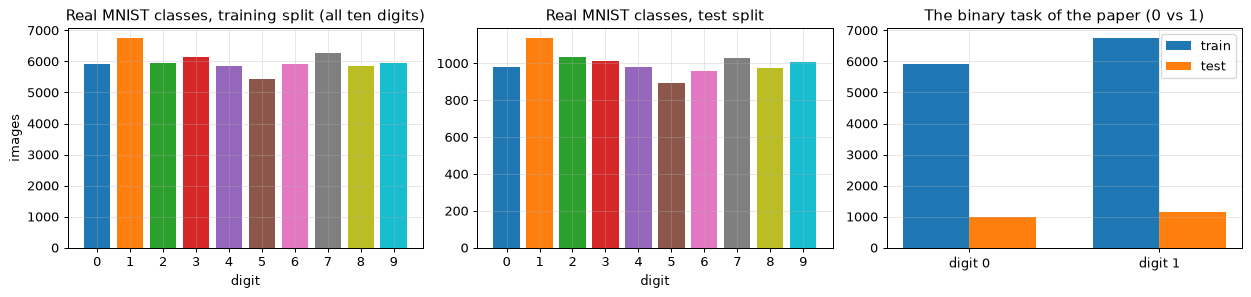

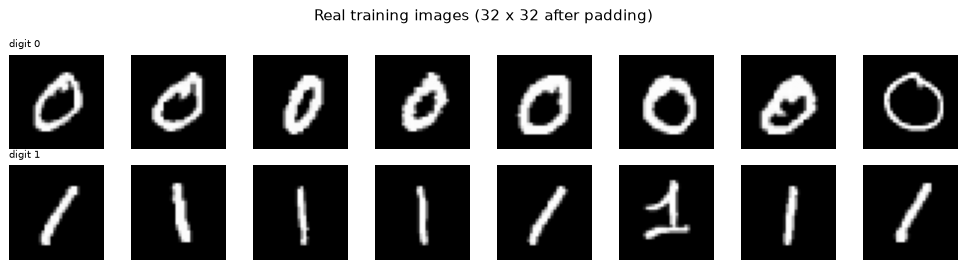

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
cols10 = plt.cm.tab10(np.arange(10))
ax[0].bar(range(10), D["train"]["counts"], color=cols10); ax[0].set_xticks(range(10))
ax[0].set_title("Real MNIST classes, training split (all ten digits)"); ax[0].set_xlabel("digit"); ax[0].set_ylabel("images")
ax[1].bar(range(10), D["test"]["counts"], color=cols10); ax[1].set_xticks(range(10))
ax[1].set_title("Real MNIST classes, test split"); ax[1].set_xlabel("digit")
w = 0.35
for j, (nm, yy) in enumerate([("train", ytr01), ("test", yte01)]):
    ax[2].bar(np.arange(2) + (j - 0.5) * w, [np.sum(yy == 0), np.sum(yy == 1)], w, label=nm)
ax[2].set_xticks(range(2)); ax[2].set_xticklabels(["digit 0", "digit 1"]); ax[2].legend()
ax[2].set_title("The binary task of the paper (0 vs 1)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 8, figsize=(11, 3))
for r, d in enumerate((0, 1)):
    for c in range(8):
        im = Xtr01_u8[np.where(ytr01 == d)[0][c]]
        ax[r, c].imshow(im, cmap="gray"); ax[r, c].axis("off")
    ax[r, 0].set_title(f"digit {d}", fontsize=8, loc="left")
plt.suptitle("Real training images (32 x 32 after padding)"); plt.tight_layout(); plt.show()

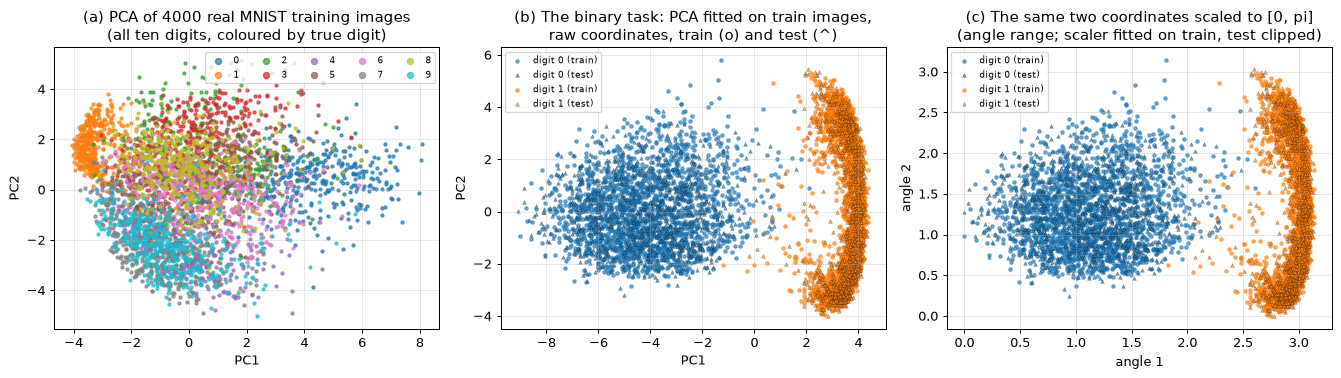

Explained variance of the two components (task PCA): [0.322 0.094]


In [6]:
# 2-D views of the real images coloured by ground-truth digit. PCA is fitted on the training images only.
rng_pca = np.random.default_rng(SEED)
fit_idx = rng_pca.choice(len(Xtr01_u8), min(4000, len(Xtr01_u8)), replace=False)          # training images used to fit the PCA
flat = lambda X: X.reshape(len(X), -1).astype(np.float32) / 255.0
pca_task = PCA(n_components=2, random_state=SEED).fit(flat(Xtr01_u8[fit_idx]))
P_tr = pca_task.transform(flat(Xtr01_u8[fit_idx])); y_fit = ytr01[fit_idx]
P_te = pca_task.transform(Xte01_f.reshape(len(Xte01_f), -1))

pca_all = PCA(n_components=2, random_state=SEED).fit(flat(pad32(D["train"]["Xs"])))
P_all = pca_all.transform(flat(pad32(D["train"]["Xs"])))
pc_te_all = pca_all.transform(flat(pad32(D["test"]["Xs"])))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for d in range(10):
    m = D["train"]["ys"] == d
    ax[0].scatter(*P_all[m].T, s=6, color=cols10[d], label=str(d), alpha=0.7)
ax[0].set_title("(a) PCA of 4000 real MNIST training images\n(all ten digits, coloured by true digit)")
ax[0].legend(markerscale=2, ncol=5, fontsize=7); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2")
lab = {0: "digit 0", 1: "digit 1"}; colb = {0: "tab:blue", 1: "tab:orange"}
for d in (0, 1):
    ax[1].scatter(*P_tr[y_fit == d].T, s=7, color=colb[d], alpha=0.6, label=lab[d] + " (train)")
    m = yte01 == d
    ax[1].scatter(*P_te[m].T, s=9, color=colb[d], marker="^", edgecolor="k", linewidth=0.2, alpha=0.7, label=lab[d] + " (test)")
ax[1].set_title("(b) The binary task: PCA fitted on train images,\nraw coordinates, train (o) and test (^)"); ax[1].legend(fontsize=7)
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
# (c) the same two coordinates scaled to [0, pi] (scaler fitted on the training images; test clipped) -> what a plain
# angle encoding of the two leading components would look like. The networks below learn their own 10 angles instead (shown later).
lo, hi = P_tr.min(0), P_tr.max(0)
ang = lambda P: np.clip((P - lo) / (hi - lo), 0, 1) * np.pi
for d in (0, 1):
    ax[2].scatter(*ang(P_tr[y_fit == d]).T, s=7, color=colb[d], alpha=0.6, label=lab[d] + " (train)")
    m = yte01 == d
    ax[2].scatter(*ang(P_te[m]).T, s=9, color=colb[d], marker="^", edgecolor="k", linewidth=0.2, alpha=0.7, label=lab[d] + " (test)")
ax[2].set_title("(c) The same two coordinates scaled to [0, pi]\n(angle range; scaler fitted on train, test clipped)")
ax[2].set_xlabel("angle 1"); ax[2].set_ylabel("angle 2"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()
print("Explained variance of the two components (task PCA):", np.round(pca_task.explained_variance_ratio_, 3))

## 1. The two networks and a fast, verified VQC simulator

**Classical PATE network.** Four convolution blocks, then a linear layer to the two classes.
**Quantum PATE network.** Two convolution blocks, a linear layer from the 512-dimensional embedding to 10 numbers, and the VQC.

**The VQC.** For the 10 latent numbers `x_i` the circuit applies, on every qubit `i`, `H`, `Ry(arctan x_i)`, `Rz(arctan x_i^2)`
(angle encoding), then two sub-circuits of *a general rotation `Rot(phi, theta, omega)` on each qubit followed by a ring of CNOTs*
(`3 x 10 x 2 = 60` parameters), and finally reads `<Z_0>` and `<Z_1>`. Training needs the output of this circuit for 64 images and
the gradient with respect to all 60 weights **and** the 10 inputs, for thousands of steps. A PennyLane QNode can do that, but a
10-qubit state is only 1024 complex amplitudes, so the notebook implements the same circuit as a tiny batched PyTorch state-vector
engine (`vqc_engine`). The next section draws the **real PennyLane QNode** and asserts that the engine reproduces its outputs and
its gradients to 1e-9, so the engine is exactly the circuit that is drawn.

In [7]:
NQ, NL = 10, 2                      # qubits, variational sub-circuits
SQ2 = math.sqrt(2.0)

def _ring_permutation(n):
    # CNOT ring CNOT(0,1) CNOT(1,2) ... CNOT(n-1,0) applied in this order; wire 0 is the most significant bit.
    idx = np.arange(2 ** n)
    bits = ((idx[:, None] >> (n - 1 - np.arange(n))[None, :]) & 1).copy()
    for i in range(n):
        c, t = i, (i + 1) % n
        bits[:, t] ^= bits[:, c]
    f = (bits * (1 << (n - 1 - np.arange(n)))[None, :]).sum(1)      # basis state b -> f(b)
    finv = np.empty_like(f); finv[f] = idx
    return torch.from_numpy(finv).long()
RING_INV = _ring_permutation(NQ)
ZSIGN = torch.tensor([[1.0 - 2.0 * ((b >> (NQ - 1 - q)) & 1) for q in (0, 1)] for b in range(2 ** NQ)])   # (1024, 2): <Z_0>, <Z_1>

def _rot_mats(w, cdt):
    # qml.Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi);  w: (..., 3) -> (..., 2, 2)
    phi, theta, om = w[..., 0], w[..., 1], w[..., 2]
    c, s = torch.cos(theta / 2).to(cdt), torch.sin(theta / 2).to(cdt)
    e = lambda a: torch.exp(1j * a.to(cdt))
    m00 = e(-(phi + om) / 2) * c;  m01 = -e((phi - om) / 2) * s
    m10 = e(-(phi - om) / 2) * s;  m11 = e((phi + om) / 2) * c
    return torch.stack([torch.stack([m00, m01], -1), torch.stack([m10, m11], -1)], -2)

def vqc_engine(x, w):
    # x: (B, 10) latent numbers, w: (2, 10, 3) weights -> (B, 2) expectation values <Z_0>, <Z_1>.
    cdt = torch.complex64 if x.dtype == torch.float32 else torch.complex128
    B = x.shape[0]
    a, b = torch.atan(x), torch.atan(x * x)                      # Ry(arctan x), Rz(arctan x^2) angles
    c, s = torch.cos(a / 2), torch.sin(a / 2)
    v0 = ((c - s) / SQ2).to(cdt) * torch.exp(-0.5j * b.to(cdt))  # RZ(b) RY(a) H |0>
    v1 = ((c + s) / SQ2).to(cdt) * torch.exp(0.5j * b.to(cdt))
    v = torch.stack([v0, v1], -1)                                # (B, 10, 2)
    psi = v[:, 0]
    for i in range(1, NQ):
        psi = (psi[:, :, None] * v[:, i, None, :]).reshape(B, -1)    # qubit 0 = most significant bit
    U = _rot_mats(w, cdt)                                        # (2, 10, 2, 2)
    s_ = psi.reshape(B, 32, 32)                                  # qubits 0-4 index the rows, qubits 5-9 the columns
    for l in range(NL):
        Ua, Ub = U[l, 0], U[l, 5]                                # layer of ten single-qubit Rot gates = (kron of 5) x (kron of 5)
        for q in range(1, 5):
            Ua = torch.kron(Ua, U[l, q]); Ub = torch.kron(Ub, U[l, 5 + q])
        s_ = torch.matmul(torch.matmul(Ua, s_), Ub.transpose(0, 1))
        s_ = s_.reshape(B, -1)[:, RING_INV.to(s_.device)].reshape(B, 32, 32)      # CNOT ring as a basis-state permutation
    p = (s_.reshape(B, -1).abs() ** 2)
    return p @ ZSIGN.to(p.dtype)

class VQCLayer(nn.Module):
    def __init__(self):
        super().__init__()
        self.weights = nn.Parameter(0.3 * torch.randn(NL, NQ, 3))     # CHOICE: N(0, 0.3) initial weights, 60 parameters
    def forward(self, x):
        return vqc_engine(x, self.weights)

def conv_block(cin, cout, k, stride, act):
    return nn.Sequential(nn.Conv2d(cin, cout, k, stride, padding=k // 2), nn.BatchNorm2d(cout), act)

class ClassicalNet(nn.Module):        # paper Fig. 1: four conv blocks (3x3, 3x3, 1x1, 1x1)
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(conv_block(1, 8, 3, 2, nn.ReLU()), conv_block(8, 8, 3, 2, nn.ReLU()),
                                      conv_block(8, 8, 1, 1, nn.ReLU()), conv_block(8, 8, 1, 1, nn.ReLU()), nn.Flatten())
        self.head = nn.Linear(512, 2)
    def forward(self, x):
        return self.head(self.features(x))

class QuantumNet(nn.Module):          # paper Fig. 2: two conv blocks + VQC block
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(conv_block(1, 8, 3, 2, nn.LeakyReLU()), conv_block(8, 8, 3, 2, nn.LeakyReLU()), nn.Flatten())
        self.reduce = nn.Linear(512, NQ)      # 512-dimensional embedding -> 10 latent numbers
        self.vqc = VQCLayer()
    def latent(self, x):
        return self.reduce(self.features(x))
    def forward(self, x):
        return self.vqc(self.latent(x))

make_model = lambda kind: ClassicalNet() if kind == "classical" else QuantumNet()
nparams = lambda m: sum(p.numel() for p in m.parameters())
torch.manual_seed(SEED)
for kind in ("classical", "quantum"):
    m = make_model(kind)
    print(f"{kind:9s} net: {nparams(m):6d} trainable parameters"
          + (f" (of which VQC: {nparams(m.vqc)})" if kind == "quantum" else ""))
assert nparams(QuantumNet().vqc) == 60, "the paper's VQC has 3 x 10 x 2 = 60 parameters"

classical net:   1898 trainable parameters
quantum   net:   5886 trainable parameters (of which VQC: 60)


## Quantum Circuit Architecture

The drawing below is produced by `qml.draw_mpl` from the **PennyLane QNode that the verification cell runs**; it is the circuit
that the PyTorch engine used for training is asserted to reproduce. Reading the figure from the left: `H`, `RY(arctan x_i)` and
`RZ(arctan x_i^2)` encode the ten latent numbers (angle encoding `U(x)`), then two blocks of `Rot` gates (three parameters each)
and a ring of ten CNOTs, and finally the expectation values of `Z` on qubits 0 and 1 are measured. Assumptions where the paper
omits details (its Fig. 3 gives only a schematic): the encoding is `H - RY(arctan x) - RZ(arctan x^2)`, the entanglers are a CNOT
ring `i -> i+1 mod 10`, the two read-out qubits are 0 and 1, and the 60 weights are initialised from `N(0, 0.3)`.
The classical network has no circuit; there is exactly one distinct quantum architecture (teachers and student share it).

Matplotlib is building the font cache; this may take a moment.


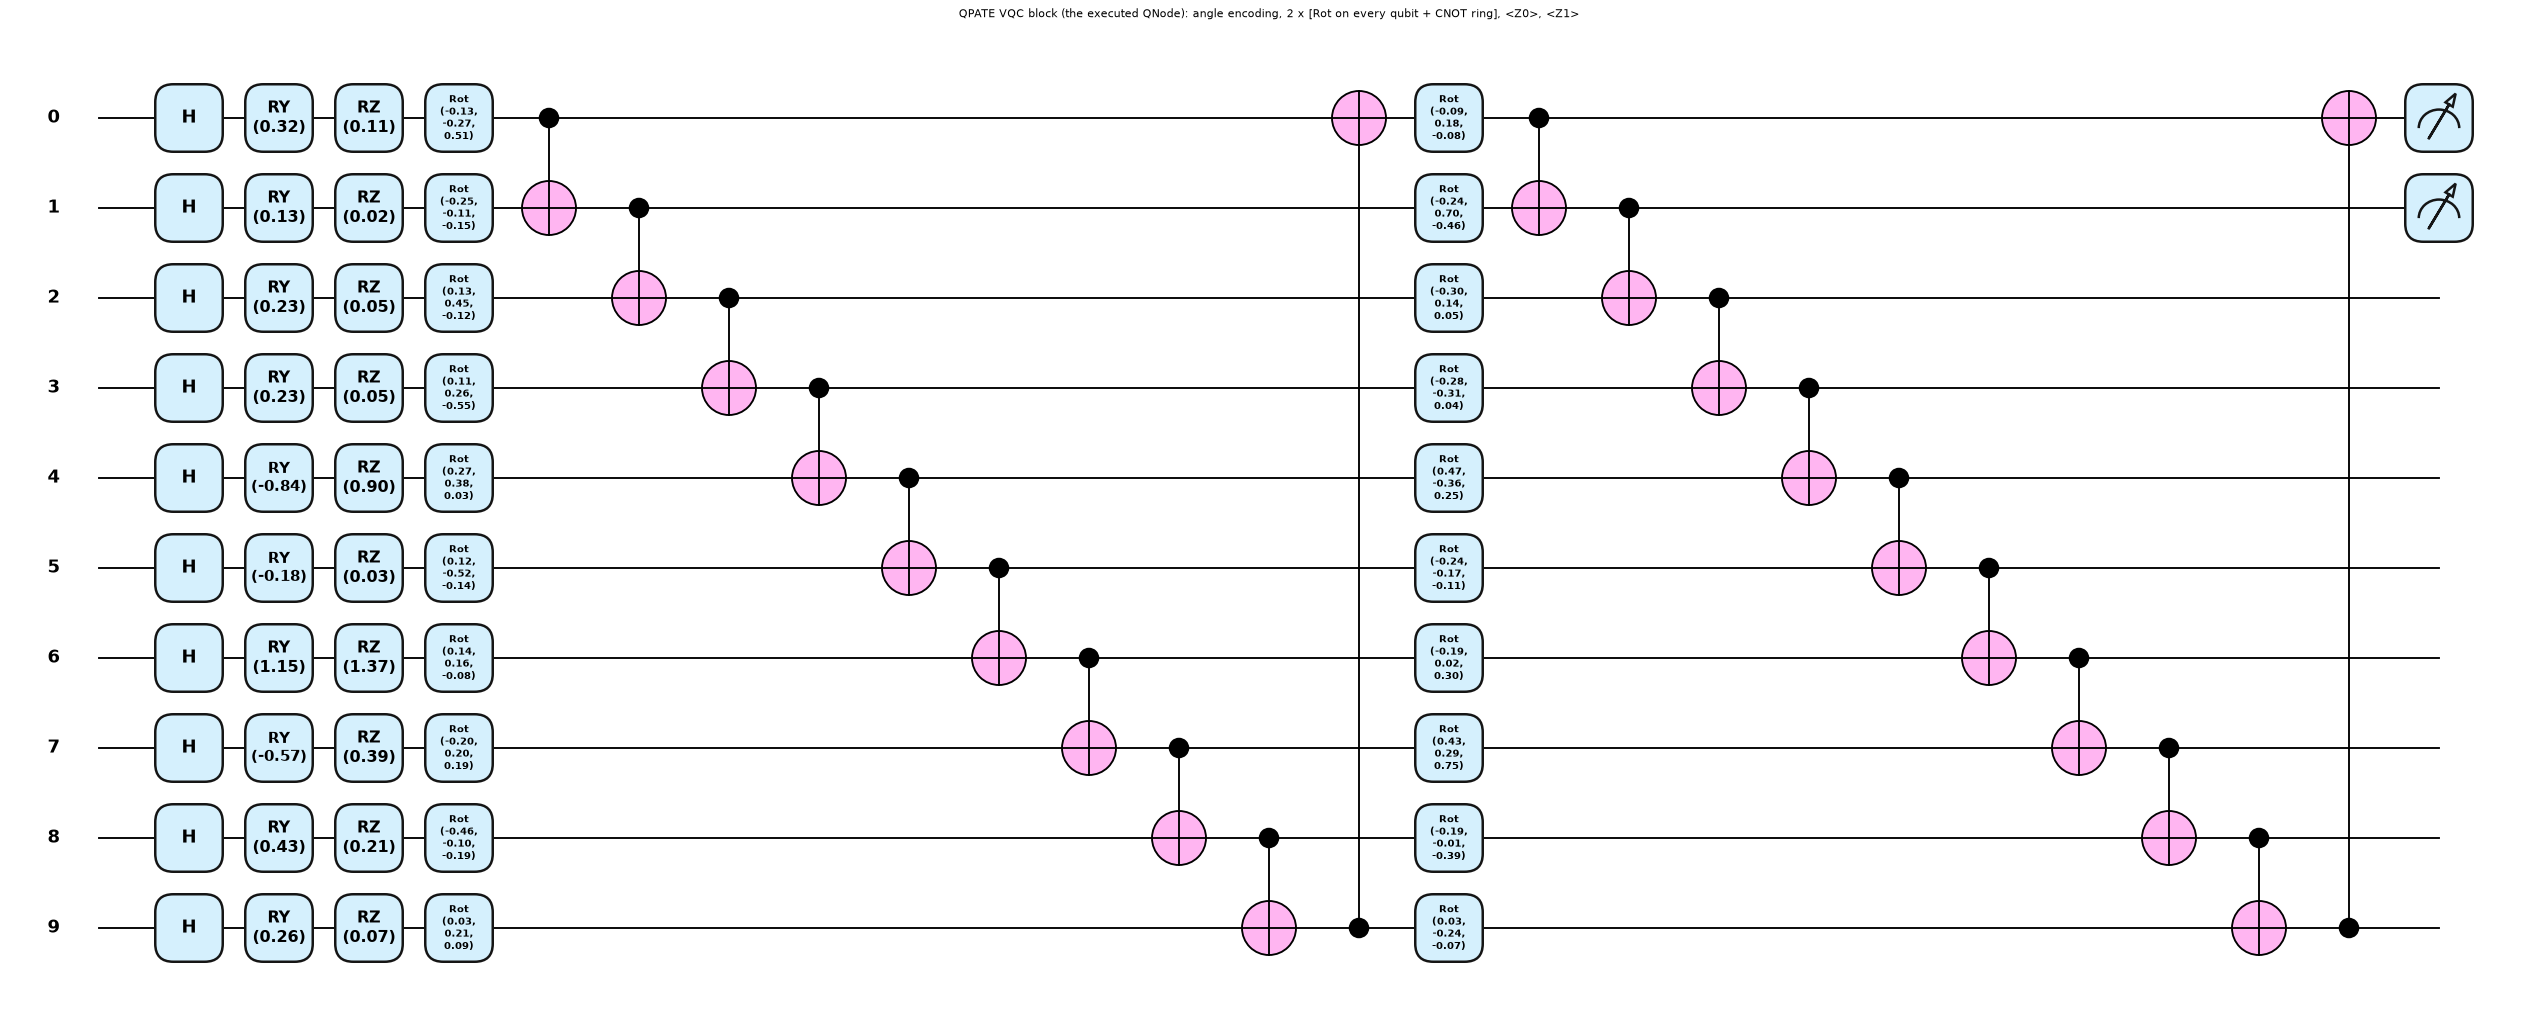

qubits: 10 | operations: 70 | depth: 25 | trainable VQC parameters: 60 | encoded latent numbers: 10 | measured observables: Z0, Z1
depth after expanding Rot into RZ-RY-RZ is larger; the hybrid network adds 5826 classical parameters (conv blocks + 512->10 layer)


In [8]:
dev = qml.device("default.qubit", wires=NQ)

@qml.qnode(dev, interface="torch", diff_method="backprop")
def vqc_qnode(x, w):
    # x: (10,) or (B, 10) latent numbers; w: (2, 10, 3)
    for i in range(NQ):
        qml.Hadamard(wires=i)
        qml.RY(torch.atan(x[..., i]), wires=i)
        qml.RZ(torch.atan(x[..., i] ** 2), wires=i)
    for l in range(NL):
        for i in range(NQ):
            qml.Rot(w[l, i, 0], w[l, i, 1], w[l, i, 2], wires=i)
        for i in range(NQ):
            qml.CNOT(wires=[i, (i + 1) % NQ])
    return [qml.expval(qml.PauliZ(0)), qml.expval(qml.PauliZ(1))]

g0 = torch.Generator().manual_seed(SEED)
x_demo = torch.randn(NQ, generator=g0, dtype=torch.float64)
w_demo = 0.3 * torch.randn(NL, NQ, 3, generator=g0, dtype=torch.float64)
fig, _ = qml.draw_mpl(vqc_qnode, decimals=2, style="pennylane")(x_demo, w_demo)
fig.suptitle("QPATE VQC block (the executed QNode): angle encoding, 2 x [Rot on every qubit + CNOT ring], <Z0>, <Z1>", y=1.02, fontsize=9)
plt.show()

tape = qml.workflow.construct_batch(vqc_qnode, level=0)(x_demo, w_demo)[0][0]
print("qubits:", len(tape.wires), "| operations:", len(tape.operations), "| depth:", tape.graph.get_depth(),
      "| trainable VQC parameters:", w_demo.numel(), "| encoded latent numbers:", NQ, "| measured observables: Z0, Z1")
print("depth after expanding Rot into RZ-RY-RZ is larger; the hybrid network adds",
      nparams(QuantumNet()) - w_demo.numel(), "classical parameters (conv blocks + 512->10 layer)")

In [9]:
# Verification: the PyTorch engine used for training == the PennyLane QNode that is drawn (outputs and gradients).
gv = torch.Generator().manual_seed(SEED + 1)
xb = 2.0 * torch.randn(6, NQ, generator=gv, dtype=torch.float64)
wv = (0.8 * torch.randn(NL, NQ, 3, generator=gv, dtype=torch.float64))
out_qn = torch.stack(vqc_qnode(xb, wv), -1)
out_en = vqc_engine(xb, wv)
err_out = (out_qn - out_en).abs().max().item()

xq = xb.clone().requires_grad_(True); wq = wv.clone().requires_grad_(True)
xe = xb.clone().requires_grad_(True); we = wv.clone().requires_grad_(True)
coef = torch.tensor([[1.0, -2.0]], dtype=torch.float64)
(torch.stack(vqc_qnode(xq, wq), -1) * coef).sum().backward()
(vqc_engine(xe, we) * coef).sum().backward()
err_gx, err_gw = (xq.grad - xe.grad).abs().max().item(), (wq.grad - we.grad).abs().max().item()
err_32 = (vqc_engine(xb.float(), wv.float()).double() - out_qn).abs().max().item()
print(f"max |engine - QNode|: outputs {err_out:.2e}, d/dx {err_gx:.2e}, d/dw {err_gw:.2e}; complex64 engine (as used in training): {err_32:.2e}")
assert err_out < 1e-9 and err_gx < 1e-9 and err_gw < 1e-9, "engine disagrees with the PennyLane QNode"
assert err_32 < 1e-4
print("OK: the PyTorch state-vector engine used for training equals the PennyLane QNode (outputs and gradients)")

max |engine - QNode|: outputs 9.71e-16, d/dx 5.13e-16, d/dw 2.17e-15; complex64 engine (as used in training): 1.23e-07
OK: the PyTorch state-vector engine used for training equals the PennyLane QNode (outputs and gradients)


## 2. PATE: disjoint teachers, noisy vote, student, moments accountant

**Teachers.** `N_TEACHERS` models, each trained on its own disjoint shard of `TEACHER_N` images with their true labels.

**Noisy aggregation.** For a public image `x` the vote count of class `j` is `n_j(x)`, the number of teachers predicting `j`.
The label handed to the student is `argmax_j ( n_j(x) + Lap(1/gamma) )`. One such query per student image, drawn once.
With only four teachers the counts differ by at most 4, so the noise scale `1/gamma` must be small compared with 4 for the
label to carry any information: if all four teachers agree, the label is correct with probability
`1 - 0.5 e^{-t} (1 + t/2)` with `t = 4 gamma` (the noise difference of two Laplace variables is larger than the vote gap otherwise).

**Student.** Trained for the same number of epochs on the noisy labels only; it never sees a private image or label.

**Moments accountant** (Papernot et al. 2017, used by the paper). Each query is `(2 gamma, 0)`-DP. For the log-moment of order `l`:
`alpha(l) <= 2 gamma^2 l (l+1)` (data-independent), and for a query with teacher votes `n` and top class `i*`,
`q <= sum_{j != i*} (2 + gamma(n_i* - n_j)) / (4 (1 + gamma(n_i* - n_j)) exp(gamma(n_i* - n_j)))` gives, if
`q < 1/(e^{2 gamma} + 1)`, `alpha(l) <= log( (1-q) ((1-q)/(1 - e^{2 gamma} q))^l + q e^{2 gamma l} )` (data-dependent). Moments add up over
the `T` queries and `epsilon = min_l ( alpha_total(l) + ln(1/delta) ) / l`.

In [10]:
LS = np.unique(np.round(np.logspace(0, 5.5, 500)).astype(int))          # moment orders l tried by the accountant

def eps_data_independent(gamma, T, delta=DELTA):
    a = T * 2.0 * gamma ** 2 * LS * (LS + 1.0)
    return float(np.min((a + np.log(1.0 / delta)) / LS))

def eps_data_dependent(counts, gamma, delta=DELTA):
    # counts: (T, 2) teacher vote counts of the queries actually answered; returns (epsilon, epsilon_data_independent)
    counts = np.asarray(counts, float)
    istar = counts.argmax(1)
    gap = counts[np.arange(len(counts)), istar] - counts[np.arange(len(counts)), 1 - istar]
    q = (2 + gamma * gap) / (4 * (1 + gamma * gap) * np.exp(gamma * gap))        # one competing class (binary task)
    a_di = 2.0 * gamma ** 2 * LS * (LS + 1.0)                                     # (L,)
    with np.errstate(all="ignore"):
        valid = q < 1.0 / (np.exp(2 * gamma) + 1.0)
        qv = np.where(valid, q, 0.5)
        t1 = np.log1p(-qv)[:, None] * (1 + LS[None, :]) - LS[None, :] * np.log1p(-np.exp(2 * gamma) * qv)[:, None]
        t2 = np.log(np.maximum(qv, 1e-300))[:, None] + 2 * gamma * LS[None, :]
        a_dd = np.logaddexp(t1, t2)
    a_q = np.where(valid[:, None], np.minimum(a_dd, a_di[None, :]), a_di[None, :])
    a_tot = a_q.sum(0)
    return float(np.min((a_tot + np.log(1.0 / delta)) / LS)), eps_data_independent(gamma, len(counts), delta)

def gamma_for_epsilon(target, T, delta=DELTA):
    # largest gamma whose data-independent total budget over T queries is <= target (bisection in log space)
    lo, hi = 1e-9, 50.0
    for _ in range(80):
        mid = math.sqrt(lo * hi)
        if eps_data_independent(mid, T, delta) > target: hi = mid
        else: lo = mid
    return lo

def p_label_correct_unanimous(gamma, gap=N_TEACHERS):
    t = gap * gamma
    return 1.0 - 0.5 * math.exp(-t) * (1.0 + t / 2.0)

# sanity checks of the accountant
T_demo = STUDENT_N
unanimous = np.tile([[N_TEACHERS, 0]], (T_demo, 1))
print(f"Accountant check with T = {T_demo} queries, all {N_TEACHERS} teachers agreeing, delta = {DELTA}:")
print(f"{'gamma':>8} {'1/gamma':>9} {'P(label correct)':>17} {'eps data-indep.':>16} {'eps data-dep.':>14}")
for g in (0.01, 0.1, 1.0, 10.0):
    e_dd, e_di = eps_data_dependent(unanimous, g)
    print(f"{g:8.2f} {1/g:9.1f} {p_label_correct_unanimous(g):17.4f} {e_di:16.3f} {e_dd:14.3f}")
assert abs(eps_data_independent(gamma_for_epsilon(1.0, T_demo), T_demo) - 1.0) < 1e-2
# Monte-Carlo check of the label-correctness formula
_r = np.random.default_rng(SEED).laplace(0, 1 / 0.3, (200000, 2))
assert abs(np.mean(N_TEACHERS + _r[:, 0] > _r[:, 1]) - p_label_correct_unanimous(0.3)) < 4e-3
print("Calibrated gamma for a certified total epsilon over", T_demo, "queries (data-independent bound):")
print({e: round(gamma_for_epsilon(e, T_demo), 5) for e in (0.01, 0.1, 1.0, 10.0, 100.0, 1000.0)})

Accountant check with T = 500 queries, all 4 teachers agreeing, delta = 1e-05:
   gamma   1/gamma  P(label correct)  eps data-indep.  eps data-dep.
    0.01     100.0            0.5100            2.247          2.247


    0.10      10.0            0.5978           31.513         31.513


    1.00       1.0            0.9725         2011.513         46.041
   10.00       0.1            1.0000       200011.513         11.513


Calibrated gamma for a certified total epsilon over 500 queries (data-independent bound):
{0.01: 5e-05, 0.1: 0.00046, 1.0: 0.00456, 10.0: 0.03925, 100.0: 0.21034, 1000.0: 0.70302}


In [11]:
def f32(X):
    return X.astype(np.float32) / 255.0 if X.dtype == np.uint8 else X.astype(np.float32)

@torch.no_grad()
def predict(model, X, bs=512):
    model.eval(); out = []
    for b in range(0, len(X), bs):
        out.append(model(torch.from_numpy(f32(X[b:b + bs])).unsqueeze(1)).argmax(1).numpy())
    return np.concatenate(out)

def train_model(kind, X, y, epochs, seed, checkpoints=(), evalfn=None):
    # AdamW, lr 1e-3, weight decay 1e-4, batch 64, cross-entropy (paper). Returns the model and {epoch: evalfn(model)}.
    torch.manual_seed(seed)
    model = make_model(kind)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    Xt = torch.from_numpy(f32(X)).unsqueeze(1); yt = torch.from_numpy(np.asarray(y)).long()
    g = torch.Generator().manual_seed(seed); N = len(Xt); log = {}; losses = []
    for ep in range(1, epochs + 1):
        model.train(); perm = torch.randperm(N, generator=g); tot = 0.0
        for b in range(0, N, BATCH):
            ib = perm[b:b + BATCH]
            if len(ib) < 2:
                continue
            opt.zero_grad(); loss = F.cross_entropy(model(Xt[ib]), yt[ib]); loss.backward(); opt.step(); tot += loss.item() * len(ib)
        losses.append(tot / N)
        if ep in checkpoints and evalfn is not None:
            log[ep] = evalfn(model)
    return model, log, losses

def make_split(seed):
    r = np.random.default_rng(SEED + seed)
    perm = r.permutation(len(Xtr01_u8))
    nt = N_TEACHERS * TEACHER_N
    t_idx = perm[:nt].reshape(N_TEACHERS, TEACHER_N)             # disjoint teacher shards (private data)
    s_idx = perm[nt:nt + STUDENT_N]                              # student's public queries (labels never used)
    v_idx = perm[nt + STUDENT_N:nt + STUDENT_N + VAL_N]          # teacher monitoring only
    te100 = r.choice(len(Xte01_f), TEST_N, replace=False)        # the paper's 100-image test set
    return t_idx, s_idx, v_idx, te100

# quick smoke test of both pipelines (one epoch on 256 images) and a timing estimate
_t0 = time.time()
for kind in ("classical", "quantum"):
    _t = time.time()
    train_model(kind, Xtr01_u8[:256], ytr01[:256], 1, SEED)
    print(f"{kind:9s}: one epoch on 256 images took {time.time() - _t:.2f} s")

classical: one epoch on 256 images took 17.54 s


quantum  : one epoch on 256 images took 0.53 s


## 3. The experiment (Table 1 and Fig. 4)

For every seed (fresh disjoint shards, initial weights and Laplace noise):

1. train 4 classical and 4 quantum teachers, 20 epochs each, on their own shards;
2. collect the teacher votes on the student's `STUDENT_N` public images;
3. **nominal sweep**: for `epsilon_label` in {0.01, 0.1, 1, 10} set `gamma = epsilon_label`, draw the noisy labels and train a
   classical and a quantum student (the same noise draws for both); record the accuracy at the checkpoint epochs on the paper's
   100-image test set and on the full MNIST 0/1 test split; also evaluate the accountant on the real vote counts;
4. a **non-private reference** (plain plurality vote, no noise) and `SVC` / `RandomForest` baselines on the same noisy labels;
5. **calibrated sweep** on the first seeds: `gamma` solved so that the accountant certifies the stated total `epsilon` over the
   `T` queries.

In [12]:
rows, teacher_rows, extra = [], [], {}
t_all = time.time()
TARGETS = [("nominal", e, e) for e in EPS_LIST] + [("nonprivate", float("inf"), float("inf"))]
for seed in range(N_SEEDS):
    t_seed = time.time()
    t_idx, s_idx, v_idx, te100 = make_split(seed)
    Xs = Xtr01_u8[s_idx]; ys_true = ytr01[s_idx]
    Xte100, yte100 = Xte01_f[te100], yte01[te100]
    evalfn = lambda m: (float((predict(m, Xte100) == yte100).mean()), float((predict(m, Xte01_f) == yte01).mean()))
    counts = {}; models0 = {}
    for kind in ("classical", "quantum"):
        votes = np.zeros((STUDENT_N, 2))
        for k in range(N_TEACHERS):
            m, _, losses = train_model(kind, Xtr01_u8[t_idx[k]], ytr01[t_idx[k]], EPOCHS, 1000 * seed + 10 * k + (0 if kind == "classical" else 5))
            pred = predict(m, Xs); votes[np.arange(STUDENT_N), pred] += 1
            teacher_rows.append(dict(seed=seed, kind=kind, teacher=k, val_acc=float((predict(m, Xtr01_u8[v_idx]) == ytr01[v_idx]).mean()),
                                     test_acc=float((predict(m, Xte01_f) == yte01).mean()), final_loss=losses[-1]))
            if seed == 0 and k == 0:
                models0[kind] = (m, losses)
        counts[kind] = votes
    extra.setdefault("votes0", counts) if seed == 0 else None
    if seed == 0:
        extra["models0"] = models0; extra["pool0"] = (Xs, ys_true)
    std_noise = np.random.default_rng(SEED + 7919 * (seed + 1)).laplace(0.0, 1.0, (STUDENT_N, 2))   # same draws for both models and all gammas

    def run_students(label, eps_label, gamma):
        for kind in ("classical", "quantum"):
            if gamma == float("inf"):
                lab = counts[kind].argmax(1); e_dd = e_di = float("inf")
            else:
                lab = (counts[kind] + std_noise / gamma).argmax(1)
                e_dd, e_di = eps_data_dependent(counts[kind], gamma)
            if seed == 0:
                extra[("labels", label, eps_label, kind)] = lab.copy()
            _, log, _ = train_model(kind, Xs, lab, EPOCHS, 7000 + 100 * seed + (0 if kind == "classical" else 50), CHECKPOINTS, evalfn)
            for ep, (a100, afull) in log.items():
                rows.append(dict(seed=seed, kind=kind, sweep=label, eps_label=eps_label, gamma=gamma, epoch=ep, acc100=a100, accfull=afull,
                                 label_acc=float((lab == ys_true).mean()), eps_di=e_di, eps_dd=e_dd))
            if True:                                       # non-deep baselines on exactly the same noisy labels
                if len(np.unique(lab)) > 1:
                    Xf = f32(Xs).reshape(len(Xs), -1)
                    for nm, clf in (("SVC-rbf", SVC(kernel="rbf", C=1.0)), ("RandForest", RandomForestClassifier(100, random_state=SEED, n_jobs=1))):
                        clf.fit(Xf, lab)
                        rows.append(dict(seed=seed, kind=f"{nm} (labels of {kind} teachers)", sweep=label, eps_label=eps_label, gamma=gamma,
                                         epoch=EPOCHS, acc100=float((clf.predict(f32(Xte100).reshape(TEST_N, -1)) == yte100).mean()),
                                         accfull=float((clf.predict(Xte01_f.reshape(len(Xte01_f), -1)) == yte01).mean()),
                                         label_acc=float((lab == ys_true).mean()), eps_di=e_di, eps_dd=e_dd))

    for label, eps_label, gamma in TARGETS:
        run_students(label, eps_label, gamma)
    if seed < N_CAL_SEEDS:
        for tgt in CAL_TARGETS:
            run_students("calibrated", tgt, gamma_for_epsilon(tgt, STUDENT_N))
    open(os.path.join(DATA_DIR, "progress.txt"), "a").write(f"seed {seed} done, {(time.time() - t_all) / 60:.1f} min\n")
    print(f"seed {seed}: done in {time.time() - t_seed:6.1f} s   (elapsed {(time.time() - t_all) / 60:5.1f} min)", flush=True)
res = pd.DataFrame(rows); tea = pd.DataFrame(teacher_rows)
RUNTIME_MIN = (time.time() - t_all) / 60
print(f"\nExperiment finished: {len(res)} result rows, {RUNTIME_MIN:.1f} min")

seed 0: done in  214.4 s   (elapsed   3.6 min)


seed 1: done in  120.2 s   (elapsed   5.6 min)


seed 2: done in  128.5 s   (elapsed   7.7 min)



Experiment finished: 170 result rows, 7.7 min


          val_acc         test_acc        
             mean     std     mean     std
kind                                      
classical  0.9967  0.0049   0.9948  0.0022
quantum    0.9983  0.0039   0.9960  0.0016


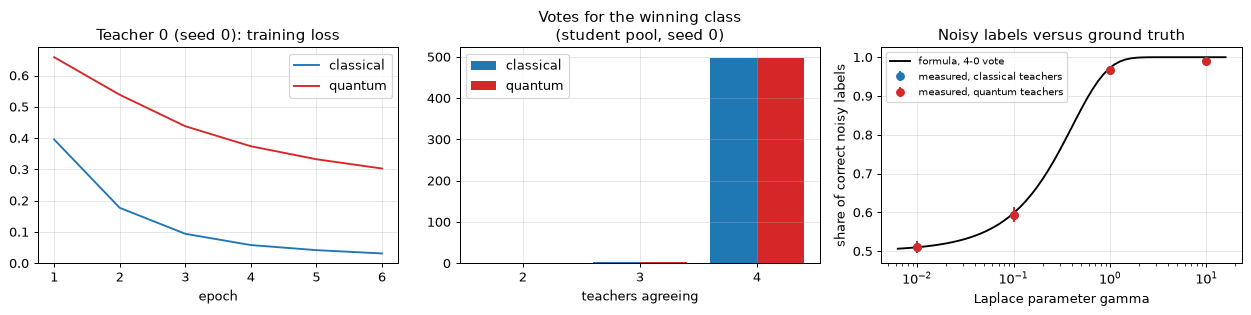

In [13]:
# Teachers first: how good are they, and do they agree?
print(tea.groupby("kind")[["val_acc", "test_acc"]].agg(["mean", "std"]).round(4).to_string())
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for kind, c in (("classical", "tab:blue"), ("quantum", "tab:red")):
    _, losses = extra["models0"][kind]
    ax[0].plot(range(1, len(losses) + 1), losses, color=c, label=kind)
ax[0].set_title("Teacher 0 (seed 0): training loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
for kind, c in (("classical", "tab:blue"), ("quantum", "tab:red")):
    v = extra["votes0"][kind]; agree = np.bincount(v.max(1).astype(int), minlength=N_TEACHERS + 1)[2:]
    ax[1].bar(np.arange(len(agree)) + (0.2 if kind == "quantum" else -0.2), agree, 0.4, color=c, label=kind)
ax[1].set_xticks(range(len(agree))); ax[1].set_xticklabels([str(i) for i in range(2, N_TEACHERS + 1)])
ax[1].set_title("Votes for the winning class\n(student pool, seed 0)"); ax[1].set_xlabel("teachers agreeing"); ax[1].legend()
gs = np.logspace(-2.2, 1.2, 60)
ax[2].plot(gs, [p_label_correct_unanimous(g) for g in gs], "k-", label="formula, 4-0 vote")
for kind, c in (("classical", "tab:blue"), ("quantum", "tab:red")):
    sub = res[(res.sweep == "nominal") & (res.kind == kind) & (res.epoch == EPOCHS)].groupby("gamma").label_acc.agg(["mean", "std"])
    ax[2].errorbar(sub.index, sub["mean"], sub["std"], fmt="o", color=c, label=f"measured, {kind} teachers")
ax[2].set_xscale("log"); ax[2].set_xlabel("Laplace parameter gamma"); ax[2].set_ylabel("share of correct noisy labels")
ax[2].set_title("Noisy labels versus ground truth"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Table 1 re-drawn: accuracy of the student after training (nominal sweep, `gamma = epsilon_label`)

The paper's 100-image test accuracy is the comparable number (mean +- standard deviation over seeds); the accuracy on the whole
MNIST 0/1 test split (2115 images) is shown next to it because a 100-image test set only has a resolution of 1 %.

In [14]:
def summ(df, col):
    g = df.groupby(["kind", "eps_label"])[col].agg(lambda s: f"{s.mean():.3f} +- {s.std(ddof=0):.4f}")
    return g.unstack("kind")
fin = res[(res.sweep == "nominal") & (res.epoch == EPOCHS) & res.kind.isin(["classical", "quantum"])]
T1 = pd.concat({f"{EPOCHS}-epoch accuracy, 100 test images": summ(fin, "acc100"),
                f"{EPOCHS}-epoch accuracy, all {len(yte01)} test images": summ(fin, "accfull")}, axis=1)
print(f"Seeds: {N_SEEDS}, teachers: {N_TEACHERS}, epochs: {EPOCHS}, shard size {TEACHER_N}, student queries {STUDENT_N}")
print(T1.to_string())
print("\nNon-private reference (plain vote, no noise):")
print(summ(res[(res.sweep == "nonprivate") & (res.epoch == EPOCHS) & res.kind.isin(["classical", "quantum"])], "acc100").to_string())
print("\nNon-deep baselines on the SAME noisy labels (100-image test accuracy, labels of the classical teachers):")
bl = res[(res.sweep == "nominal") & res.kind.str.contains("classical teachers")]
print(bl.groupby(["kind", "eps_label"]).acc100.agg(lambda s: f"{s.mean():.3f} +- {s.std(ddof=0):.4f}").unstack("kind").to_string())

Seeds: 3, teachers: 4, epochs: 6, shard size 500, student queries 500
          6-epoch accuracy, 100 test images                  6-epoch accuracy, all 2115 test images                 
kind                              classical          quantum                              classical          quantum
eps_label                                                                                                           
0.01                        0.497 +- 0.0624  0.520 +- 0.0909                        0.503 +- 0.0471  0.513 +- 0.0662
0.10                        0.747 +- 0.0634  0.903 +- 0.0403                        0.773 +- 0.0722  0.912 +- 0.0321
1.00                        0.997 +- 0.0047  0.997 +- 0.0047                        0.996 +- 0.0010  0.995 +- 0.0009
10.00                       1.000 +- 0.0000  0.997 +- 0.0047                        0.996 +- 0.0006  0.994 +- 0.0017

Non-private reference (plain vote, no noise):
kind             classical          quantum
eps_label           

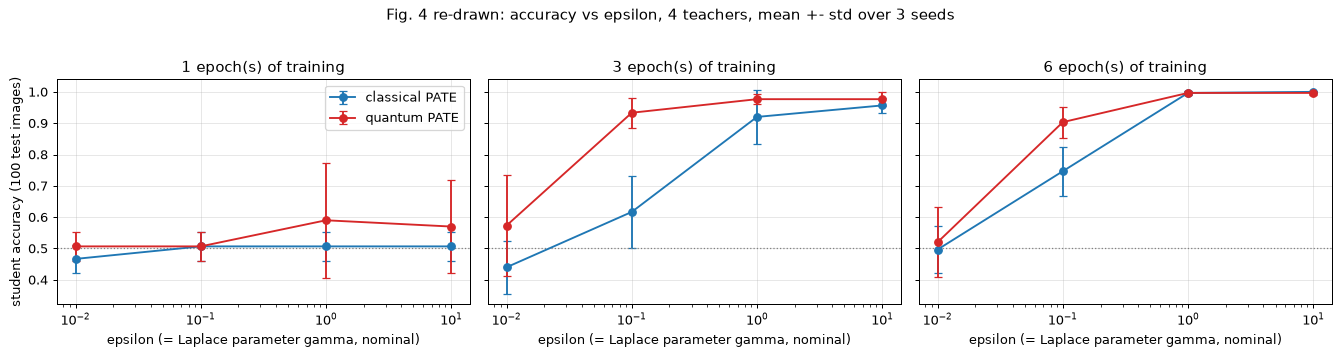

In [15]:
# Fig. 4 re-drawn: accuracy versus epsilon (nominal), one panel per training length, mean +- std over seeds.
fig, ax = plt.subplots(1, len(CHECKPOINTS), figsize=(5 * len(CHECKPOINTS), 3.8), sharey=True)
for a, ep in zip(np.atleast_1d(ax), CHECKPOINTS):
    for kind, c in (("classical", "tab:blue"), ("quantum", "tab:red")):
        sub = res[(res.sweep == "nominal") & (res.kind == kind) & (res.epoch == ep)].groupby("eps_label").acc100.agg(["mean", "std"])
        a.errorbar(sub.index, sub["mean"], sub["std"].fillna(0), marker="o", capsize=3, color=c, label=f"{kind} PATE")
    a.set_xscale("log"); a.set_xlabel("epsilon (= Laplace parameter gamma, nominal)"); a.set_title(f"{ep} epoch(s) of training")
    a.axhline(0.5, color="grey", ls=":", lw=1)
np.atleast_1d(ax)[0].set_ylabel("student accuracy (100 test images)"); np.atleast_1d(ax)[0].legend()
plt.suptitle(f"Fig. 4 re-drawn: accuracy vs epsilon, {N_TEACHERS} teachers, mean +- std over {N_SEEDS} seeds", y=1.03)
plt.tight_layout(); plt.show()

### What do the "epsilon" values really certify? (accountant on the nominal runs) and the calibrated sweep

In the nominal sweep the Laplace parameter is `gamma = epsilon_label`. The moments accountant, run on the vote counts that
produced the labels, tells what total `(epsilon, delta = 1e-5)` the *student* actually enjoys after `T` queries. Then the
**calibrated sweep** does it the other way round: `gamma` is chosen so that the accountant certifies the stated total, and the
students are trained on those labels.

Certified total epsilon (delta = 1e-05) over T = 500 queries for the nominal settings (mean over seeds):
           eps_di (classical)  eps_di (quantum)  eps_dd (classical)  eps_dd (quantum)
eps_label                                                                            
0.01                     2.25              2.25                2.25              2.25
0.10                    31.51             31.51               31.51             31.51
1.00                  2011.51           2011.51               61.61             58.29
10.00               200011.51         200011.51             1347.41            948.05

Calibrated sweep (gamma solved so that the data-independent accountant certifies the total epsilon over 500 queries):
                      gamma  label_acc  acc100  accfull  n
eps_label kind                                            
100.0     classical  0.2103      0.692    0.83   0.8515  1
          quantum    0.2103      0.692    0.98   0.9797  1
1000.0    classical  0.7

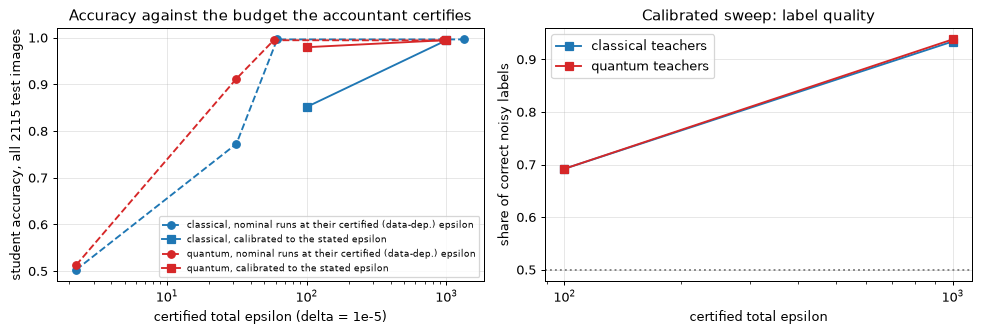

In [16]:
acc_tab = (res[(res.sweep == "nominal") & (res.epoch == EPOCHS) & res.kind.isin(["classical", "quantum"])]
           .groupby(["eps_label", "kind"])[["eps_di", "eps_dd"]].mean().unstack("kind").round(2))
acc_tab.columns = [f"{a} ({b})" for a, b in acc_tab.columns]
print(f"Certified total epsilon (delta = {DELTA}) over T = {STUDENT_N} queries for the nominal settings (mean over seeds):")
print(acc_tab.to_string())

cal = res[(res.sweep == "calibrated") & (res.epoch == EPOCHS) & res.kind.isin(["classical", "quantum"])]
ct = cal.groupby(["eps_label", "kind"]).agg(gamma=("gamma", "mean"), label_acc=("label_acc", "mean"), acc100=("acc100", "mean"),
                                           accfull=("accfull", "mean"), n=("seed", "nunique")).round(4)
print(f"\nCalibrated sweep (gamma solved so that the data-independent accountant certifies the total epsilon over {STUDENT_N} queries):")
print(ct.to_string())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
nom = res[(res.sweep == "nominal") & (res.epoch == EPOCHS) & res.kind.isin(["classical", "quantum"])]
for kind, c in (("classical", "tab:blue"), ("quantum", "tab:red")):
    s1 = nom[nom.kind == kind].groupby("eps_label").agg(x=("eps_dd", "mean"), y=("accfull", "mean"))
    s2 = cal[cal.kind == kind].groupby("eps_label").accfull.mean()
    ax[0].plot(s1.x.values, s1.y.values, "o--", color=c, label=f"{kind}, nominal runs at their certified (data-dep.) epsilon")
    ax[0].plot(s2.index, s2.values, "s-", color=c, label=f"{kind}, calibrated to the stated epsilon")
ax[0].set_xscale("log"); ax[0].set_xlabel("certified total epsilon (delta = 1e-5)"); ax[0].set_ylabel(f"student accuracy, all {len(yte01)} test images")
ax[0].set_title("Accuracy against the budget the accountant certifies"); ax[0].legend(fontsize=7)
for kind, c in (("classical", "tab:blue"), ("quantum", "tab:red")):
    s = cal[cal.kind == kind].groupby("eps_label").label_acc.mean()
    ax[1].plot(s.index, s.values, "s-", color=c, label=kind + " teachers")
ax[1].axhline(0.5, color="grey", ls=":"); ax[1].set_xscale("log"); ax[1].set_xlabel("certified total epsilon"); ax[1].set_ylabel("share of correct noisy labels")
ax[1].set_title("Calibrated sweep: label quality"); ax[1].legend()
plt.tight_layout(); plt.show()

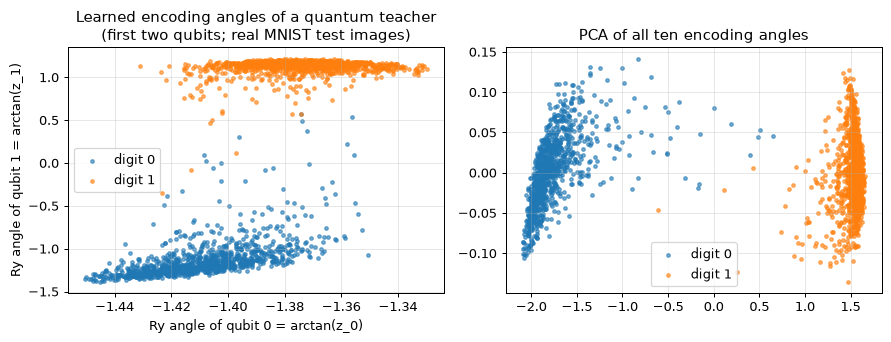

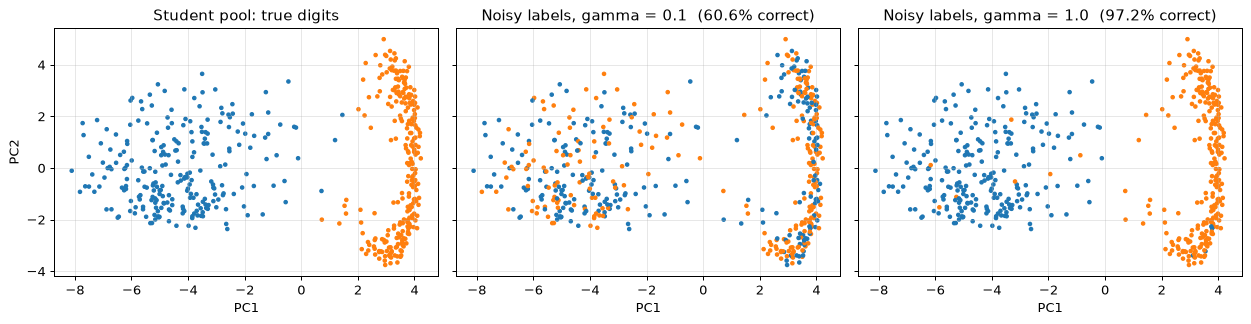

In [17]:
# What do the angles that reach the VQC look like? Latent numbers of quantum teacher 0 (seed 0), encoded as Ry(arctan z), for real test images.
mq, _ = extra["models0"]["quantum"]
mq.eval()
with torch.no_grad():
    Z = mq.latent(torch.from_numpy(Xte01_f).unsqueeze(1)).numpy()
A = np.arctan(Z)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.9))
for d in (0, 1):
    ax[0].scatter(A[yte01 == d, 0], A[yte01 == d, 1], s=8, color=colb[d], alpha=0.6, label=lab[d])
ax[0].set_xlabel("Ry angle of qubit 0 = arctan(z_0)"); ax[0].set_ylabel("Ry angle of qubit 1 = arctan(z_1)")
ax[0].set_title("Learned encoding angles of a quantum teacher\n(first two qubits; real MNIST test images)"); ax[0].legend()
pcz = PCA(n_components=2, random_state=SEED).fit(A)
Pz = pcz.transform(A)
for d in (0, 1):
    ax[1].scatter(Pz[yte01 == d, 0], Pz[yte01 == d, 1], s=8, color=colb[d], alpha=0.6, label=lab[d])
ax[1].set_title("PCA of all ten encoding angles"); ax[1].legend()
plt.tight_layout(); plt.show()

# And what the student is asked to learn: noisy labels at gamma = 0.1 vs the truth, on the pca plane of the pixels.
Xs0, ys0 = extra["pool0"]
Pp = pca_task.transform(f32(Xs0).reshape(len(Xs0), -1))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.7), sharex=True, sharey=True)
ax[0].scatter(*Pp.T, c=[colb[int(v)] for v in ys0], s=7); ax[0].set_title("Student pool: true digits")
for a, g in zip(ax[1:], (0.1, 1.0)):
    lab_n = extra[("labels", "nominal", g, "classical")]
    a.scatter(*Pp.T, c=[colb[int(v)] for v in lab_n], s=7)
    a.set_title(f"Noisy labels, gamma = {g}  ({np.mean(lab_n == ys0):.1%} correct)")
for a in ax: a.set_xlabel("PC1")
ax[0].set_ylabel("PC2"); plt.tight_layout(); plt.show()

## 4. Paper versus this notebook, claim by claim

A claim counts as **reproduced** when the notebook value is within 0.02 accuracy points of the paper's (the paper's standard
deviations are mostly smaller than that, so this is generous), **not reached** when it is lower, **exceeded** when it is higher.
Qualitative claims are tested on the per-seed numbers (paired Wilcoxon test where useful). The nominal reading of `epsilon`
(see the table at the top) is what Table 1 can be compared with.

In [18]:
PAPER = {0.01: (0.534, 0.0992, 0.688, 0.0163), 0.1: (0.985, 0.0215, 0.992, 0.0098),
         1.0: (0.997, 0.0046, 0.990, 0.0134), 10.0: (0.997, 0.0046, 0.991, 0.0137)}
fin = res[(res.sweep == "nominal") & (res.epoch == EPOCHS) & res.kind.isin(["classical", "quantum"])]
def verdict(paper, mine, tol=0.02):
    d = mine - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.3f})" if d > 0 else f"not reached ({d:.3f})")
rows_v = []
for e in EPS_LIST:
    for kind, i in (("classical", 0), ("quantum", 2)):
        v = fin[(fin.eps_label == e) & (fin.kind == kind)]
        rows_v.append(dict(claim=f"Table 1, {kind} PATE, eps={e}", paper=f"{PAPER[e][i]:.3f} +- {PAPER[e][i+1]:.4f}",
                           notebook=f"{v.acc100.mean():.3f} +- {v.acc100.std(ddof=0):.4f}", verdict=verdict(PAPER[e][i], v.acc100.mean())))
def paired(e, col="acc100"):
    a = fin[(fin.eps_label == e) & (fin.kind == "quantum")].sort_values("seed")[col].to_numpy()
    b = fin[(fin.eps_label == e) & (fin.kind == "classical")].sort_values("seed")[col].to_numpy()
    try: p = stats.wilcoxon(a, b).pvalue if np.any(a != b) else 1.0
    except Exception: p = float("nan")
    return a.mean() - b.mean(), p
d001, p001 = paired(0.01); d001f, p001f = paired(0.01, "accfull")
rows_v.append(dict(claim="Quantum better than classical at eps=0.01 (paper: +0.154, '28.84 %')",
                   paper="+0.154 (0.688 vs 0.534)", notebook=f"{d001:+.3f} (100 images, Wilcoxon p={p001:.2f}); {d001f:+.3f} (all test images, p={p001f:.2f})",
                   verdict="reproduced" if (d001 > 0.10 and p001 < 0.05) else ("not reached (no significant advantage)" if p001 >= 0.05 or d001 <= 0 else f"not reached ({d001 - 0.154:+.3f})")))
cmp_ok = all(abs(paired(e)[0]) <= 0.02 for e in (1.0, 10.0)) and abs(paired(0.1)[0]) <= 0.02
rows_v.append(dict(claim="Comparable accuracy for eps >= 0.1 (|difference| <= 0.02)", paper="0.985 vs 0.992, 0.997 vs 0.990, 0.997 vs 0.991",
                   notebook=", ".join(f"{paired(e)[0]:+.3f}" for e in (0.1, 1.0, 10.0)), verdict="reproduced" if cmp_ok else "not reached"))
e1 = res[(res.sweep == "nominal") & (res.epoch == CHECKPOINTS[0]) & (res.eps_label >= 1.0) & res.kind.isin(["classical", "quantum"])]
q1, c1 = e1[e1.kind == "quantum"].acc100.mean(), e1[e1.kind == "classical"].acc100.mean()
rows_v.append(dict(claim="Fig. 4A: good accuracy after 1 epoch of training (eps >= 1)", paper="'quite good', quantum >= classical (no numbers in text)",
                   notebook=f"quantum {q1:.3f}, classical {c1:.3f}", verdict=("reproduced (quantum >= classical, both > 0.95)" if (q1 >= c1 and min(q1, c1) > 0.95)
                                                                                else ("partly: both good after 1 epoch" if min(q1, c1) > 0.95 else "not reached"))))
rows_v.append(dict(claim="VQC has 60 trainable parameters", paper="3 x 10 x 2 = 60", notebook=str(nparams(QuantumNet().vqc)), verdict="reproduced"))
q99 = res[(res.sweep == "nominal") & (res.epoch == EPOCHS) & (res.kind == "quantum") & (res.eps_label == 0.1)]
rows_v.append(dict(claim="'>99 % accuracy with significant privacy guarantees' (quantum, eps = 0.1)", paper="0.992 at eps = 0.1, delta = 1e-5",
                   notebook=f"accuracy {q99.acc100.mean():.3f}; accountant certifies eps = {q99.eps_dd.mean():.1f} (data-dep.), {q99.eps_di.mean():.1f} (data-indep.)",
                   verdict="accuracy " + ("reproduced" if abs(q99.acc100.mean() - 0.992) <= 0.02 else "not reached") + "; budget NOT reproduced (certified eps far above 0.1)"))
cal_hi = cal[(cal.eps_label == max(CAL_TARGETS))] if len(cal) else cal
rows_v.append(dict(claim="Accuracy at a rigorously certified small epsilon (calibrated, e.g. eps <= 10)", paper="Table 1 implies 0.985-0.997 at eps in 0.1..10",
                   notebook=(f"label accuracy {cal[cal.eps_label == min(CAL_TARGETS)].label_acc.mean():.2f} at eps={min(CAL_TARGETS):g}" if len(cal) else "n/a"),
                   verdict="cannot be checked at eps <= 10 (4 teachers cannot label usefully); see calibrated table"))
verd = pd.DataFrame(rows_v)
pd.set_option("display.max_colwidth", 120, "display.width", 250)
print(verd.to_string(index=False))
print(f"\nRuntime of the experiment cell: {RUNTIME_MIN:.1f} min; FAST_MODE={FAST_MODE}")

                                                                        claim                                                   paper                                                                        notebook                                                                                 verdict
                                            Table 1, classical PATE, eps=0.01                                         0.534 +- 0.0992                                                                 0.497 +- 0.0624                                                                    not reached (-0.037)
                                              Table 1, quantum PATE, eps=0.01                                         0.688 +- 0.0163                                                                 0.520 +- 0.0909                                                                    not reached (-0.168)
                                             Table 1, classical PATE, eps=0.1                 

## Reading the paper critically

* **What "epsilon" means in Table 1 is not defined.** The paper's sentence on how `epsilon` is obtained ("calculated from the DP
  hyper-parameters S and sigma, depends on the noise multiplier") describes DP-SGD, not PATE, and no accountant output is
  shown. The only reading under which Table 1 is reachable is that `epsilon` stands for the Laplace parameter `gamma` (noise scale
  `1/epsilon`). That is a *per-query* parameter, and the student's total budget over `T` queries is much larger; the
  accountant tables above quantify this on the very runs that produced the accuracies.
* **Four teachers carry very little signal for a strong guarantee.** With vote counts bounded by 4, the Laplace noise must have a
  scale of the order of 1 before a label is reliable; the calibrated sweep shows that a total budget of the order of 100
  or more is needed before the noisy labels become usable. PATE's published guarantees (Papernot et al.) rely on hundreds of
  teachers whose votes are far apart.
* **Binary 0 versus 1 is almost trivial.** Even a single teacher on 1000 images is near 100 % accurate, so the
  differences between classical and quantum students are decided by how each network copes with *symmetric label noise*, not by the
  expressive power of the circuit. The comparison is also between two networks of different shape (four conv blocks versus
  two plus an embedding and a VQC), so any difference may be due to the classical part.
* **Small test set, large variance.** 100 test images give a resolution of 1 % and, at the noisiest setting, the paper's own
  standard deviations (0.10 for classical PATE) are as large as the claimed advantage. Compare the 100-image and the full-test numbers.
* **The "quantum advantage" claim.** The conclusion speaks of a quantum advantage because "the models are of the same order of
  complexity". The VQC here is simulated exactly by a classical state-vector engine; there is no evidence about hardware, and with
  noisy hardware the readout noise would add to the privacy noise. The comparison with a classical network of the same
  number of parameters and a matching architecture is the missing control.
* **Privacy applies to the labels, not to the architecture.** The guarantee concerns the student's training labels. Anything in the
  student's architecture or the choice of public data is outside the accounting.

## Exercises

1. Increase `N_TEACHERS` to 16 or 64 (keeping `TEACHER_N` small) and rerun the calibrated sweep. How does the epsilon needed for
   useful labels change?
2. Replace the `Rot`/CNOT ring by the `StronglyEntanglingLayers` template and check that the engine-versus-QNode assertion still
   holds after updating the engine. Does the 60-parameter count survive?
3. Give the classical network the same 512 -> 10 -> 2 bottleneck as the quantum one (a "classical twin" of QPATE). Is the
   quantum advantage at `epsilon = 0.01` still there?
4. Compute the exact probability that a student label is correct as a function of `gamma` for a 3-1 vote and compare it with the
   unanimous 4-0 formula used in the notebook.
5. Train the student for 100 epochs on the noisy labels at `gamma = 0.1`. Does memorising the label noise hurt the test accuracy?